# exp03: Ablation Sensor

Membandingkan fitur gabungan original, HRV saja, eye tracking saja, tanpa gaze/eye state, serta tanpa iris. XGBoost dan parameter referensinya dipertahankan agar perubahan hasil mengukur pengaruh kelompok fitur.

Dataset: good_acceptable, window 15 detik, langkah 5 detik. Target dibaca langsung dari cognitive_load_label (Low=0, Medium=1, High=2), termasuk Low pada fase nonpengerjaan yang sudah diberi label dalam dataset v2. Identitas, konteks CodeArrange, dan kualitas hanya menjadi metadata/pembagi evaluasi, bukan fitur prediksi.

### Konfigurasi

Memakai runtime lokal yang sudah diverifikasi terhadap artefak batch-01 lama. Run ini mengevaluasi seluruh peserta dengan seed 42 dan 300 tree/iterasi untuk model berbasis pohon. Checkpoint yang cocok dilanjutkan; hasil dengan identitas data, kode, atau environment berbeda tidak dicampur.

In [1]:
from pathlib import Path
import json
import sys

location = Path.cwd().resolve()
BATCH = next(p for p in (location, *location.parents) if (p / "shared" / "design_registry.json").is_file())
sys.path.insert(0, str(BATCH))

import pandas as pd
from IPython.display import display, Image
from shared import data, design
from shared.runner import Config, run

EXPERIMENT = "exp03"
WINDOW = "window_15s_step_5s"
DATASET_PATH = data.ROOT / "analysis_sessions" / "dataset_fusion" / "output" / "v2_session_phase" / WINDOW / "good_acceptable.csv"
config = Config(dataset_path=DATASET_PATH, output_root=BATCH / "outputs", experiment=EXPERIMENT)
print(DATASET_PATH)

D:\Penelitian Pak Hadi\Adaptive-IDE\analysis_sessions\dataset_fusion\output\v2_session_phase\window_15s_step_5s\good_acceptable.csv


### Dataset dan Kandidat

Memeriksa label, ID window, timestamp, dan allowlist sensor sebelum training. Tidak ada pemetaan ulang dari difficulty. Missing value dan fitur konstan ditangani pada training masing-masing fold, bukan secara global.

In [2]:
frame = data.load_dataset(DATASET_PATH)
display(pd.DataFrame(data.describe_data(frame)["class_counts"].items(), columns=["label", "windows"]))
specifications = design.registry(EXPERIMENT)
display(pd.DataFrame([{**{k: v for k, v in item.items() if k != "candidates"}, "candidate_count": len(item["candidates"])} for item in specifications]))
print(f"{len(frame)} windows; {frame.participant_id.nunique()} participants; {len(data.FEATURES)} base sensor features")

,label,windows
0,Low,732
1,Medium,1105
2,High,1174


,id,model,scaler,tune,variant,candidate_count
0,original,xgboost,None,False,original,1
1,hrv,xgboost,None,False,hrv,1
2,eye,xgboost,None,False,eye,1
3,no_gaze_state,xgboost,None,False,no_gaze_state,1
4,no_iris,xgboost,None,False,no_iris,1


3011 windows; 13 participants; 26 base sensor features


### Fold dan Training

Leave-one-participant-out menghasilkan satu prediksi test untuk setiap window. Tiga inner group fold, bila diperlukan tuning, hanya menggunakan peserta training. Kriteria seleksi adalah macro-F1 gabungan prediksi inner; parameter terpilih lalu dilatih ulang pada seluruh outer training. Imputasi, scaler, feature selection, dan resampling tidak melihat outer test.

Cache menyimpan hasil fit/prediksi dengan hash data, urutan ID split, pipeline, parameter, seed, kode, dan paket. Hash output diperiksa sebelum melanjutkan checkpoint.

In [3]:
folds = data.make_folds(frame)
display(pd.DataFrame([{"fold": f["fold_id"], "test_participant": f["participant_id"], "train_windows": len(f["train"]), "test_windows": len(f["test"]), "inner_folds": len(f["inner"])} for f in folds]))
RESULT_DIR = run(config)
print(RESULT_DIR)

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,2698,313,3
1,fold_01,Andreas,2825,186,3
2,fold_02,Athaya,2755,256,3
3,fold_03,Fabian,2708,303,3
4,fold_04,Rafi,2691,320,3
5,fold_05,Savitri,2724,287,3
6,fold_06,Shakilla,2897,114,3
7,fold_07,Tio,2741,270,3
8,fold_08,faqih,2718,293,3
9,fold_09,ikhsan,2792,219,3


Complete run verified: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp03\window_15s_step_5s\full_88079f045c66


D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp03\window_15s_step_5s\full_88079f045c66


### Evaluasi

Macro-F1 pooled pada tiga kelas menjadi metrik utama. Accuracy, balanced accuracy, precision/recall/F1 per kelas, dan variasi antarorang melengkapi penilaian. Kelas tanpa contoh pada test seseorang tetap kosong pada laporan kelas, bukan dianggap performa nol.

In [4]:
metrics = pd.read_csv(RESULT_DIR / "metrics.csv").sort_values("macro_f1", ascending=False)
display(metrics)
classes = pd.read_csv(RESULT_DIR / "class_metrics.csv")
display(classes[classes.scope.eq("pooled")].drop(columns=["participant_id"], errors="ignore"))
display(pd.read_csv(RESULT_DIR / "participant_summary.csv", header=[0, 1], index_col=0))

,model,accuracy,balanced_accuracy,macro_f1,windows
1,hrv,0.348389,0.332436,0.332192,3011
3,no_iris,0.307539,0.318051,0.307772,3011
4,original,0.297908,0.301788,0.295333,3011
0,eye,0.287280,0.286796,0.281874,3011
2,no_gaze_state,0.281302,0.292511,0.280010,3011


,scope,model,label,precision,recall,f1,support
0,pooled,eye,Low,0.233491,0.270492,0.250633,732
1,pooled,eye,Medium,0.330639,0.370136,0.349274,1105
2,pooled,eye,High,0.278618,0.219761,0.245714,1174
42,pooled,hrv,Low,0.233284,0.214481,0.223488,732
43,pooled,hrv,Medium,0.353181,0.391855,0.371514,1105
44,pooled,hrv,High,0.412770,0.390971,0.401575,1174
84,pooled,no_gaze_state,Low,0.236655,0.363388,0.286638,732
85,pooled,no_gaze_state,Medium,0.342155,0.327602,0.334720,1105
86,pooled,no_gaze_state,High,0.264174,0.186542,0.218672,1174
126,pooled,no_iris,Low,0.245748,0.394809,0.302935,732


accuracy                     balanced_accuracy            \
                    min    median       max               min    median   
model                                                                     
eye            0.000000  0.288889  0.411150          0.000000  0.306956   
hrv            0.070175  0.340541  0.453125          0.040816  0.334835   
no_gaze_state  0.000000  0.307087  0.413978          0.000000  0.315060   
no_iris        0.086758  0.328125  0.430108          0.107143  0.363887   
original       0.000000  0.334471  0.409449          0.000000  0.363072   

                         macro_f1                      
                    max       min    median       max  
model                                                  
eye            0.414087  0.000000  0.253690  0.389900  
hrv            0.428942  0.075472  0.271676  0.383453  
no_gaze_state  0.394205  0.000000  0.219617  0.315702  
no_iris        0.395119  0.093100  0.288504  0.359252  
original       0.401068  0.000000  0.263090  0.405268

### Confusion Matrix

Baris adalah label referensi, kolom adalah prediksi. Diagonal menunjukkan recall kelas pada gambar ternormalisasi. Maksimal enam model ditampilkan di notebook; seluruh confusion matrix tersimpan pada direktori hasil.

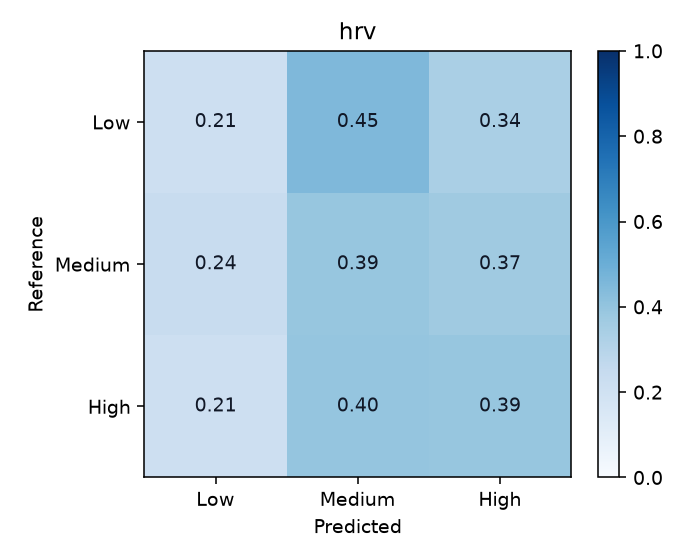

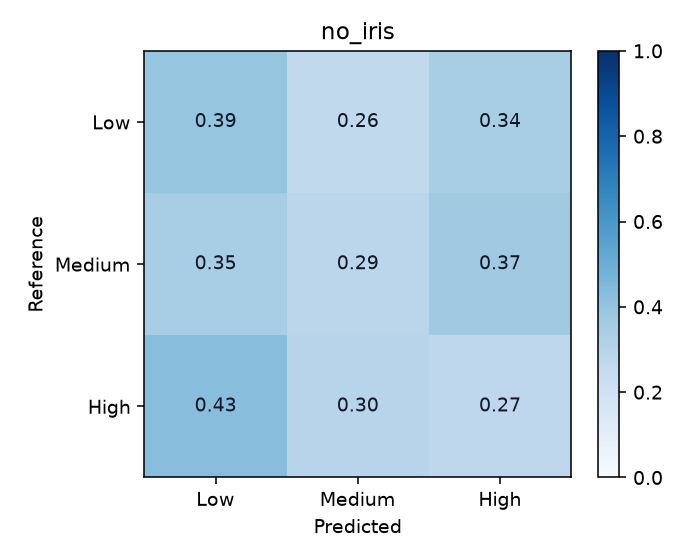

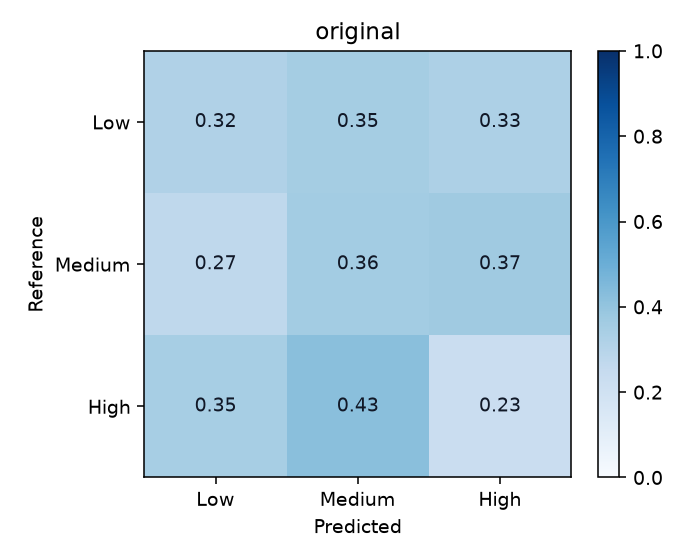

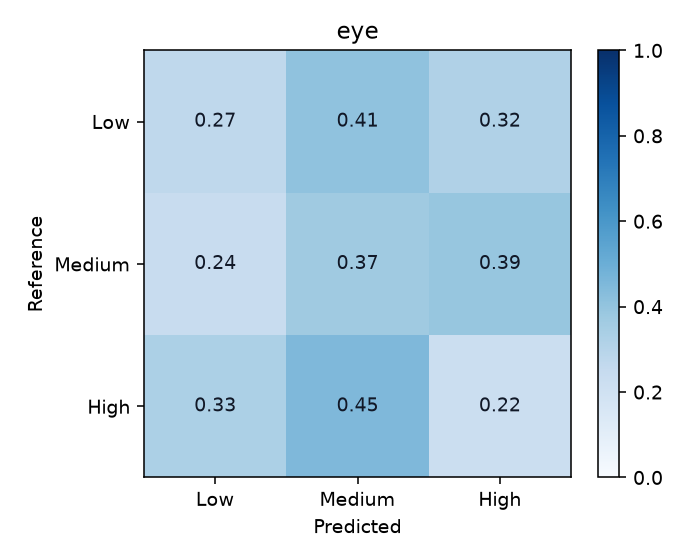

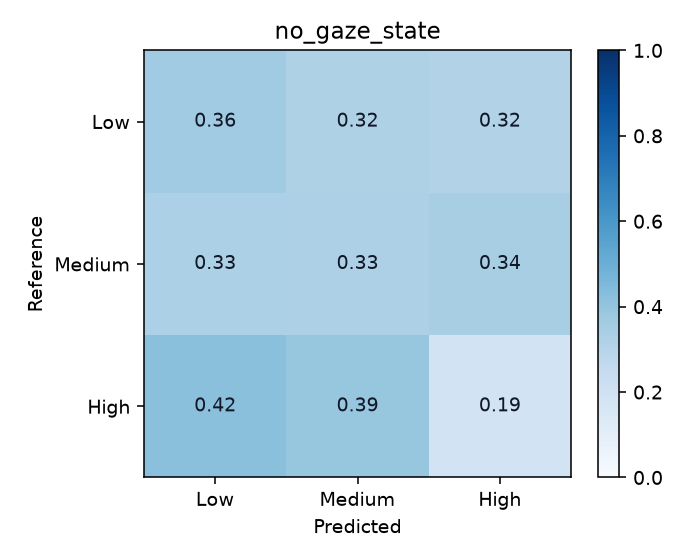

In [5]:
for name in metrics.model.head(6):
    display(Image(filename=str(RESULT_DIR / "figures" / f"{name}_normalized.png")))

### Artefak

Prediksi, manifest, pencarian kandidat, konfigurasi preprocessing, metrik, dan figure tersedia untuk audit. Bobot model dan cache disimpan lokal tetapi tidak masuk Git. Sumber dataset serta arsip old-dataset tidak diubah.

In [6]:
summary = json.loads((RESULT_DIR / "summary.json").read_text())
assert summary["status"] == "complete"
assert summary["evaluated_folds"] == frame.participant_id.nunique()
print(f"Status: {summary['status']}")
print(f"Output: {RESULT_DIR}")

Status: complete
Output: D:\Penelitian Pak Hadi\Adaptive-IDE\models\batch-01\new-dataset\outputs\exp03\window_15s_step_5s\full_88079f045c66
